# Inferencia - House Pricing

**Autor:** Roberto Farfan

Genera las predicciones de `SalePrice` para los datos crudos de `test.csv` con el pipeline de inferencia del notebook `2.0-rf-modelado`. Ese pipeline incluye todo el flujo: selección de features, ingeniería de características (notebook 1.1) y el modelo ganador (GradientBoosting), y devuelve el precio directamente en dólares.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd

from house_pricing.config import MODELS_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR

2026-10-30 20:52:05.626 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing


## Carga del pipeline de inferencia

Carga `models/pipeline_inferencia.joblib`, que ya está entrenado con todos los datos de `train.csv`. No se reentrena nada en este notebook.

In [3]:
pipeline_inferencia = joblib.load(MODELS_DIR / "pipeline_inferencia.joblib")
pipeline_inferencia

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...sample=0.8))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](79,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleType', 'SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,79
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...sample=0.8))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('seleccion', ...), ('features', ...), ...]"


## Carga de los datos crudos de test

Lee `test.csv` tal como viene de Kaggle, con `Id` como índice. El pipeline se encarga de seleccionar las columnas, imputar los faltantes y aplicar las transformaciones.

In [4]:
test = pd.read_csv(RAW_DATA_DIR / "test.csv", index_col="Id")
print(f"test: {test.shape}")
print(f"Columnas con faltantes: {test.isna().any().sum()}")

test: (1459, 79)
Columnas con faltantes: 33


## Predicciones

Aplica el pipeline completo a los datos crudos. La salida ya está en dólares.

In [5]:
predicciones = pd.Series(pipeline_inferencia.predict(test), index=test.index, name="SalePrice")

print(f"Predicciones: {len(predicciones)} | faltantes: {predicciones.isna().sum()} | negativas: {(predicciones <= 0).sum()}")
predicciones.describe().round(0).to_frame()

Predicciones: 1459 | faltantes: 0 | negativas: 0


,SalePrice
count,1459.0
mean,178185.0
std,79296.0
min,50018.0
25%,127562.0
50%,156382.0
75%,206221.0
max,673436.0


## Revisión de las predicciones

Compara la distribución de los precios predichos con la de los precios reales de `train.csv`. Deben verse parecidas: si la distribución predicha está desplazada o tiene valores fuera de rango, hay un problema en el flujo.

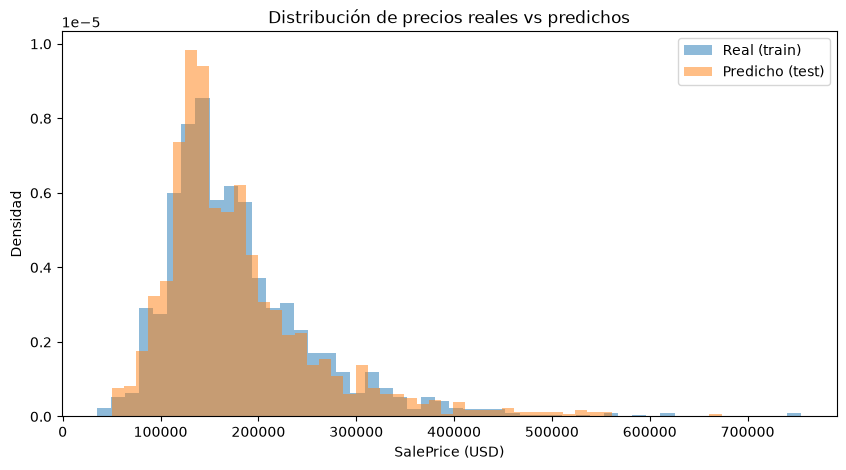

In [6]:
precios_train = pd.read_csv(RAW_DATA_DIR / "train.csv", usecols=["SalePrice"])["SalePrice"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(precios_train, bins=50, alpha=0.5, density=True, label="Real (train)")
ax.hist(predicciones, bins=50, alpha=0.5, density=True, label="Predicho (test)")
ax.set_xlabel("SalePrice (USD)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de precios reales vs predichos")
ax.legend()
plt.show()

## Guardar predicciones

Guarda las predicciones en `data/processed/predicciones_test.csv` con las columnas `Id` y `SalePrice`, el mismo formato de `sample_submission.csv` de Kaggle, y verifica que los `Id` coinciden con los de ese archivo.

In [7]:
ruta_predicciones = PROCESSED_DATA_DIR / "predicciones_test.csv"
predicciones.to_csv(ruta_predicciones, index_label="Id")

ejemplo = pd.read_csv(RAW_DATA_DIR / "sample_submission.csv")
guardado = pd.read_csv(ruta_predicciones)
assert list(guardado.columns) == list(ejemplo.columns), "Las columnas no coinciden con sample_submission.csv"
assert guardado["Id"].equals(ejemplo["Id"]), "Los Id no coinciden con sample_submission.csv"

print(f"Guardado en: {ruta_predicciones}")
guardado.head()

Guardado en: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing\data\processed\predicciones_test.csv


,Id,SalePrice
0,1461,120198.623110
1,1462,148805.797035
2,1463,181171.283347
3,1464,183162.641956
4,1465,196142.884409
